**PRE-TRANSFORM ATTENTION(BAHDANAU)**

IMPLEMENT ADDITIVE (BAHDANAU) ATTENTION FROM SCRATCH. CALCULATE THE ALIGNMENT SCORES AND THE CONTEXT VECTOR


In [1]:
# Workflow:
# 1. Download ManyThings English-French dataset
# 2. Prepare vocabulary
# 3. Numericalize and dynamically pad sequences
# 4. Build LSTM Encoder
# 5. Implement trainable Bahdanau Attention
# 6. Build Attention-based LSTM Decoder
# 7. Integrate Encoder + Attention + Decoder
# 8. Train with teacher forcing
# 9. Validate without teacher forcing
# 10. Perform standalone autoregressive inference
# 11. Visualize attention weights

In [2]:
# ARCHITECTURE
#
# English sentence
#        ↓
# Tokenization
#        ↓
# Vocabulary IDs
#        ↓
# Embedding
#        ↓
# Encoder LSTM
#        ↓
# Encoder Outputs [B,T,H]
#        │
#        ├──────────────────────┐
#        │                      │
#        ▼                      ▼
# Encoder States        Decoder Hidden
#        │                      │
#        └───────┬──────────────┘
#                ↓
#       Bahdanau Attention
#                ↓
#        Attention Weights
#                ↓
#          Context Vector
#                ↓
#       Context + Embedding
#                ↓
#          Decoder LSTM
#                ↓
#          Linear Layer
#                ↓
#       Target Word Prediction
#                ↓
#       Feed Prediction Back
#                ↓
#          Next Time Step


In [3]:
import os
import re
import zipfile
import urllib.request
import random

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn.utils.rnn import pad_sequence

import matplotlib.pyplot as plt

In [4]:
# CONFIGURATION

SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# Dataset configuration
URL = "https://www.manythings.org/anki/fra-eng.zip"

ZIP_FILE = "fra-eng.zip"

# Correct path: files extract directly to the current working directory
DATA_FILE = "fra.txt"

# Number of sentence pairs used for this classroom lab
MAX_SAMPLES = 5000

# Training configuration
BATCH_SIZE = 64

ENC_EMB_DIM = 128
DEC_EMB_DIM = 128

HIDDEN_DIM = 256

DROPOUT = 0.2

LEARNING_RATE = 0.001

CLIP = 1.0

EPOCHS_PER_STAGE = 2

# Teacher forcing schedule
TEACHER_FORCING_SCHEDULE = [
    0.75,
    0.50,
    0.25,
    0.00
]

Device: cpu


In [5]:
# DOWNLOAD DATASET

if not os.path.exists(ZIP_FILE):

    print("Downloading dataset...")

    req = urllib.request.Request(
        URL,
        headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    )

    with urllib.request.urlopen(req) as response, open(ZIP_FILE, 'wb') as out_file:
        out_file.write(response.read())

    print("Download complete.")


Download complete.


In [6]:
# EXTRACT DATASET

if not os.path.exists(DATA_FILE):

    print("Extracting dataset...")

    with zipfile.ZipFile(
        ZIP_FILE,
        "r"
    ) as zip_ref:

        zip_ref.extractall(".")

    print("Extraction complete.")


Extracting dataset...
Extraction complete.


In [7]:
# TEXT CLEANING

def clean_text(text):

    text = text.lower().strip()

    # Keep basic alphabetic characters and punctuation
    text = re.sub(
        r"[^a-zA-ZÀ-ÿ!?'.]+",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()

In [8]:
# LOAD ENGLISH-FRENCH SENTENCE PAIRS

pairs = []

with open(
    DATA_FILE,
    encoding="utf-8"
) as file:

    for line in file:

        parts = line.strip().split("\t")

        if len(parts) < 2:
            continue

        english = clean_text(parts[0])
        french = clean_text(parts[1])

        if not english or not french:
            continue

        pairs.append(
            (
                english,
                french
            )
        )

        if len(pairs) >= MAX_SAMPLES:
            break


print("Number of sentence pairs:", len(pairs))

print("\nExample pair:")
print("English:", pairs[0][0])
print("French :", pairs[0][1])


Number of sentence pairs: 5000

Example pair:
English: go.
French : va !


In [9]:
# VOCABULARY CLASS

class Vocabulary:

    def __init__(self):

        self.special_tokens = [
            "<PAD>",
            "<SOS>",
            "<EOS>",
            "<UNK>"
        ]

        self.stoi = {
            token: idx
            for idx, token
            in enumerate(self.special_tokens)
        }

        self.itos = {
            idx: token
            for idx, token
            in enumerate(self.special_tokens)
        }

    def build(self, sentences):

        for sentence in sentences:

            tokens = sentence.split()

            for token in tokens:

                if token not in self.stoi:

                    index = len(self.stoi)

                    self.stoi[token] = index
                    self.itos[index] = token

    def numericalize(self, sentence):

        tokens = sentence.split()

        indices = [
            self.stoi.get(
                token,
                self.stoi["<UNK>"]
            )
            for token in tokens
        ]

        return [
            self.stoi["<SOS>"]
        ] + indices + [
            self.stoi["<EOS>"]
        ]

    def __len__(self):

        return len(self.stoi)

In [10]:
# BUILD SOURCE AND TARGET VOCABULARIES

src_vocab = Vocabulary()
trg_vocab = Vocabulary()

src_vocab.build(
    [english for english, french in pairs]
)

trg_vocab.build(
    [french for english, french in pairs]
)

print("\nSource vocabulary size:",
      len(src_vocab))

print("Target vocabulary size:",
      len(trg_vocab))


Source vocabulary size: 1464
Target vocabulary size: 2816


In [12]:
# DATASET

class TranslationDataset(Dataset):

    def __init__(
        self,
        pairs,
        src_vocab,
        trg_vocab
    ):

        self.pairs = pairs
        self.src_vocab = src_vocab
        self.trg_vocab = trg_vocab

    def __len__(self):

        return len(self.pairs)

    def __getitem__(self, index):

        english, french = self.pairs[index]

        src = torch.tensor(
            self.src_vocab.numericalize(
                english
            ),
            dtype=torch.long
        )

        trg = torch.tensor(
            self.trg_vocab.numericalize(
                french
            ),
            dtype=torch.long
        )

        return src, trg


dataset = TranslationDataset(
    pairs,
    src_vocab,
    trg_vocab
)

In [13]:
#COLLATE FUNCTION

# Dynamic padding for every batch

PAD_IDX = src_vocab.stoi["<PAD>"]

TRG_PAD_IDX = trg_vocab.stoi["<PAD>"]


def collate_fn(batch):

    src_batch = [
        item[0]
        for item in batch
    ]

    trg_batch = [
        item[1]
        for item in batch
    ]

    # Pad source sequences
    src_batch = pad_sequence(
        src_batch,
        batch_first=True,
        padding_value=PAD_IDX
    )

    # Pad target sequences
    trg_batch = pad_sequence(
        trg_batch,
        batch_first=True,
        padding_value=TRG_PAD_IDX
    )

    return (
        src_batch,
        trg_batch
    )

In [14]:
# TRAIN / VALIDATION SPLIT

train_size = int(
    0.9 * len(dataset)
)

valid_size = len(dataset) - train_size

train_dataset, valid_dataset = random_split(
    dataset,
    [train_size, valid_size],
    generator=torch.Generator().manual_seed(SEED)
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

In [15]:
# LSTM ENCODER
class Encoder(nn.Module):

    def __init__(
        self,
        input_dim,
        embedding_dim,
        hidden_dim,
        dropout=0.2
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            input_dim,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(self, src):

        # src:
        # [B, T]

        embedded = self.dropout(
            self.embedding(src)
        )

        # embedded:
        # [B, T, E]

        outputs, (hidden, cell) = self.rnn(
            embedded
        )

        # outputs:
        # [B, T, H]
        #
        # hidden:
        # [1, B, H]
        #
        # cell:
        # [1, B, H]

        return (
            outputs,
            hidden,
            cell
        )

In [16]:
# TRAINABLE BAHDANAU ADDITIVE ATTENTION

class BahdanauAttention(nn.Module):

    def __init__(self, hidden_size):

        super().__init__()

        # Project encoder hidden states
        self.W_encoder = nn.Linear(
            hidden_size,
            hidden_size,
            bias=False
        )

        # Project decoder hidden state
        self.W_decoder = nn.Linear(
            hidden_size,
            hidden_size,
            bias=False
        )

        # Convert energy vector into
        # one scalar attention score
        self.V = nn.Linear(
            hidden_size,
            1,
            bias=False
        )

    def forward(
        self,
        decoder_hidden,
        encoder_outputs
    ):

        # decoder_hidden:
        # [B, H]

        # encoder_outputs:
        # [B, T, H]


        # ----------------------------------------------------
        # Project encoder outputs
        # ----------------------------------------------------

        encoder_projection = self.W_encoder(
            encoder_outputs
        )

        # [B, T, H]


        # ----------------------------------------------------
        # Project decoder hidden state
        # ----------------------------------------------------

        decoder_projection = self.W_decoder(
            decoder_hidden
        )

        # [B, H]


        # ----------------------------------------------------
        # Expand decoder state across source sequence
        # ----------------------------------------------------

        decoder_projection = decoder_projection.unsqueeze(1)

        # [B, 1, H]

        decoder_projection = decoder_projection.expand(
            -1,
            encoder_outputs.size(1),
            -1
        )

        # [B, T, H]


        # ----------------------------------------------------
        # Calculate Bahdanau energy
        # e_ij = V tanh(W_h h_j + W_s s_i)
        # ----------------------------------------------------

        energy = torch.tanh(
            encoder_projection +
            decoder_projection
        )

        # [B, T, H]


        # ----------------------------------------------------
        # Convert energy to scalar scores
        # ----------------------------------------------------

        scores = self.V(
            energy
        )

        # [B, T, 1]

        scores = scores.squeeze(-1)

        # [B, T]


        # ----------------------------------------------------
        # Convert scores into attention weights
        # ----------------------------------------------------

        attention_weights = torch.softmax(
            scores,
            dim=1
        )

        # [B, T]


        # ----------------------------------------------------
        # Calculate context vector
        #
        # context = sum(attention_weight * encoder_output)
        # ----------------------------------------------------

        context = torch.bmm(
            attention_weights.unsqueeze(1),
            encoder_outputs
        )

        # [B, 1, H]

        context = context.squeeze(1)

        # [B, H]

        return (
            context,
            attention_weights
        )

In [17]:
# TEST ATTENTION INDEPENDENTLY

print("\nTesting Bahdanau Attention...")

BATCH_TEST = 2
SEQ_TEST = 5
HIDDEN_TEST = 8

test_encoder_outputs = torch.randn(
    BATCH_TEST,
    SEQ_TEST,
    HIDDEN_TEST
)

test_decoder_hidden = torch.randn(
    BATCH_TEST,
    HIDDEN_TEST
)

test_attention = BahdanauAttention(
    HIDDEN_TEST
)

test_context, test_weights = test_attention(
    test_decoder_hidden,
    test_encoder_outputs
)

print(
    "Encoder outputs:",
    test_encoder_outputs.shape
)

print(
    "Decoder hidden:",
    test_decoder_hidden.shape
)

print(
    "Context:",
    test_context.shape
)

print(
    "Attention weights:",
    test_weights.shape
)

print(
    "Attention weight sums:",
    test_weights.sum(dim=1)
)



Testing Bahdanau Attention...
Encoder outputs: torch.Size([2, 5, 8])
Decoder hidden: torch.Size([2, 8])
Context: torch.Size([2, 8])
Attention weights: torch.Size([2, 5])
Attention weight sums: tensor([1.0000, 1.0000], grad_fn=<SumBackward1>)


In [18]:
# ATTENTION-BASED LSTM DECODER
class AttentionDecoder(nn.Module):

    def __init__(
        self,
        output_dim,
        embedding_dim,
        hidden_dim,
        attention,
        dropout=0.2
    ):

        super().__init__()

        self.output_dim = output_dim
        self.hidden_dim = hidden_dim

        self.embedding = nn.Embedding(
            output_dim,
            embedding_dim,
            padding_idx=TRG_PAD_IDX
        )

        self.attention = attention

        # Decoder receives:
        # word embedding + attention context
        self.rnn = nn.LSTM(
            input_size=embedding_dim + hidden_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Prediction receives:
        # decoder output + context + embedding
        self.fc_out = nn.Linear(
            embedding_dim +
            hidden_dim +
            hidden_dim,
            output_dim
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(
        self,
        input_token,
        hidden,
        cell,
        encoder_outputs
    ):

        # input_token:
        # [B]

        input_token = input_token.unsqueeze(1)

        # [B, 1]


        # ----------------------------------------------------
        # Word embedding
        # ----------------------------------------------------

        embedded = self.dropout(
            self.embedding(input_token)
        )

        # [B, 1, E]


        # ----------------------------------------------------
        # Current decoder hidden state
        # ----------------------------------------------------

        decoder_hidden = hidden[-1]

        # [B, H]


        # ----------------------------------------------------
        # Bahdanau Attention
        # ----------------------------------------------------

        context, attention_weights = self.attention(
            decoder_hidden,
            encoder_outputs
        )

        # context:
        # [B, H]

        # attention_weights:
        # [B, T]


        # ----------------------------------------------------
        # Add sequence dimension
        # ----------------------------------------------------

        context = context.unsqueeze(1)

        # [B, 1, H]


        # ----------------------------------------------------
        # Combine embedding + context
        # ----------------------------------------------------

        rnn_input = torch.cat(
            [
                embedded,
                context
            ],
            dim=2
        )

        # [B, 1, E + H]


        # ----------------------------------------------------
        # Decoder LSTM
        # ----------------------------------------------------

        output, (hidden, cell) = self.rnn(
            rnn_input,
            (hidden, cell)
        )

        # output:
        # [B, 1, H]


        # ----------------------------------------------------
        # Generate target vocabulary prediction
        # ----------------------------------------------------

        prediction_input = torch.cat(
            [
                output.squeeze(1),
                context.squeeze(1),
                embedded.squeeze(1)
            ],
            dim=1
        )

        # [B, H + H + E]

        prediction = self.fc_out(
            prediction_input
        )

        # [B, target_vocab_size]

        return (
            prediction,
            hidden,
            cell,
            attention_weights
        )

In [19]:
# COMPLETE ATTENTION Seq2Seq MODEL

class Seq2SeqAttention(nn.Module):

    def __init__(
        self,
        encoder,
        decoder,
        device
    ):

        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(
        self,
        src,
        trg,
        teacher_forcing_ratio=0.5
    ):

        batch_size = src.size(0)

        trg_len = trg.size(1)

        trg_vocab_size = self.decoder.output_dim

        # Store predictions
        outputs = torch.zeros(
            batch_size,
            trg_len,
            trg_vocab_size,
            device=self.device
        )

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        encoder_outputs, hidden, cell = self.encoder(
            src
        )

        # ----------------------------------------------------
        # First decoder input = <SOS>
        # ----------------------------------------------------

        input_token = trg[:, 0]

        # ----------------------------------------------------
        # Decode one target token at a time
        # ----------------------------------------------------

        for t in range(1, trg_len):

            output, hidden, cell, attention_weights = \
                self.decoder(
                    input_token,
                    hidden,
                    cell,
                    encoder_outputs
                )

            # Store prediction
            outputs[:, t] = output

            # Highest probability token
            predicted_token = output.argmax(
                dim=1
            )

            # Randomly decide whether to use
            # ground-truth token or model prediction
            use_teacher_forcing = (
                random.random()
                < teacher_forcing_ratio
            )

            if use_teacher_forcing:

                input_token = trg[:, t]

            else:

                input_token = predicted_token

        return outputs


In [20]:
# CREATE MODEL

INPUT_DIM = len(src_vocab)

OUTPUT_DIM = len(trg_vocab)

attention = BahdanauAttention(
    HIDDEN_DIM
)

encoder = Encoder(
    input_dim=INPUT_DIM,
    embedding_dim=ENC_EMB_DIM,
    hidden_dim=HIDDEN_DIM,
    dropout=DROPOUT
)

decoder = AttentionDecoder(
    output_dim=OUTPUT_DIM,
    embedding_dim=DEC_EMB_DIM,
    hidden_dim=HIDDEN_DIM,
    attention=attention,
    dropout=DROPOUT
)

model = Seq2SeqAttention(
    encoder,
    decoder,
    device
).to(device)


In [21]:
# CHECK TRAINABLE PARAMETERS

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "\nTrainable parameters:",
    trainable_parameters
)



Trainable parameters: 3536896


In [22]:
# LOSS AND OPTIMIZER

criterion = nn.CrossEntropyLoss(
    ignore_index=TRG_PAD_IDX
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

In [23]:
# TRAINING FUNCTION

def train_epoch(
    model,
    loader,
    optimizer,
    criterion,
    clip,
    teacher_forcing_ratio
):

    model.train()

    epoch_loss = 0

    teacher_forced_steps = 0
    predicted_steps = 0

    for src, trg in loader:

        src = src.to(device)
        trg = trg.to(device)

        optimizer.zero_grad()

        output = model(
            src,
            trg,
            teacher_forcing_ratio
        )

        # ----------------------------------------------------
        # Ignore <SOS> position during loss calculation
        # ----------------------------------------------------

        output = output[:, 1:, :]

        trg = trg[:, 1:]

        output_dim = output.size(-1)

        # Flatten predictions
        output = output.reshape(
            -1,
            output_dim
        )

        # Flatten target
        trg = trg.reshape(-1)

        # ----------------------------------------------------
        # Cross entropy loss
        # ----------------------------------------------------

        loss = criterion(
            output,
            trg
        )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        loss.backward()

        # ----------------------------------------------------
        # Gradient clipping
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            clip
        )

        # ----------------------------------------------------
        # Update parameters
        # ----------------------------------------------------

        optimizer.step()

        epoch_loss += loss.item()

        # Approximate teacher-forcing telemetry
        steps = trg.numel()

        teacher_forced_steps += (
            steps * teacher_forcing_ratio
        )

        predicted_steps += (
            steps * (1 - teacher_forcing_ratio)
        )

    average_loss = (
        epoch_loss /
        len(loader)
    )

    return (
        average_loss,
        teacher_forced_steps,
        predicted_steps
    )

In [24]:
# TRAINING FUNCTION

def train_epoch(
    model,
    loader,
    optimizer,
    criterion,
    clip,
    teacher_forcing_ratio
):

    model.train()

    epoch_loss = 0

    teacher_forced_steps = 0
    predicted_steps = 0

    for src, trg in loader:

        src = src.to(device)
        trg = trg.to(device)

        optimizer.zero_grad()

        output = model(
            src,
            trg,
            teacher_forcing_ratio
        )

        # ----------------------------------------------------
        # Ignore <SOS> position during loss calculation
        # ----------------------------------------------------

        output = output[:, 1:, :]

        trg = trg[:, 1:]

        output_dim = output.size(-1)

        # Flatten predictions
        output = output.reshape(
            -1,
            output_dim
        )

        # Flatten target
        trg = trg.reshape(-1)

        # ----------------------------------------------------
        # Cross entropy loss
        # ----------------------------------------------------

        loss = criterion(
            output,
            trg
        )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        loss.backward()

        # ----------------------------------------------------
        # Gradient clipping
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            clip
        )

        # ----------------------------------------------------
        # Update parameters
        # ----------------------------------------------------

        optimizer.step()

        epoch_loss += loss.item()

        # Approximate teacher-forcing telemetry
        steps = trg.numel()

        teacher_forced_steps += (
            steps * teacher_forcing_ratio
        )

        predicted_steps += (
            steps * (1 - teacher_forcing_ratio)
        )

    average_loss = (
        epoch_loss /
        len(loader)
    )

    return (
        average_loss,
        teacher_forced_steps,
        predicted_steps
    )

In [26]:
# VALIDATION FUNCTION
def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    epoch_loss = 0

    with torch.no_grad():

        for src, trg in loader:

            src = src.to(device)
            trg = trg.to(device)

            # No teacher forcing during validation
            output = model(
                src,
                trg,
                teacher_forcing_ratio=0.0
            )

            output = output[:, 1:, :]

            trg = trg[:, 1:]

            output_dim = output.size(-1)

            output = output.reshape(
                -1,
                output_dim
            )

            trg = trg.reshape(-1)

            loss = criterion(
                output,
                trg
            )

            epoch_loss += loss.item()

    return epoch_loss / len(loader)

In [27]:
# TRAIN MODEL WITH REDUCING TEACHER FORCING

for ratio in TEACHER_FORCING_SCHEDULE:

    print("\n" + "=" * 60)

    print(
        f"Teacher Forcing Ratio: {ratio:.2f}"
    )

    print("=" * 60)

    for epoch in range(
        EPOCHS_PER_STAGE
    ):

        train_loss, teacher_steps, predicted_steps = \
            train_epoch(
                model,
                train_loader,
                optimizer,
                criterion,
                CLIP,
                ratio
            )

        valid_loss = evaluate(
            model,
            valid_loader,
            criterion
        )

        total_steps = (
            teacher_steps +
            predicted_steps
        )

        observed_teacher_percentage = (
            teacher_steps /
            total_steps *
            100
        )

        print(
            f"Epoch {epoch + 1}"
        )

        print(
            f"Train Loss: {train_loss:.4f}"
        )

        print(
            f"Validation Loss: {valid_loss:.4f}"
        )

        print(
            f"Teacher Forcing: "
            f"{observed_teacher_percentage:.2f}%"
        )



Teacher Forcing Ratio: 0.75
Epoch 1
Train Loss: 1.2291
Validation Loss: 3.4838
Teacher Forcing: 75.00%
Epoch 2
Train Loss: 1.0494
Validation Loss: 3.5743
Teacher Forcing: 75.00%

Teacher Forcing Ratio: 0.50
Epoch 1
Train Loss: 1.0523
Validation Loss: 3.5587
Teacher Forcing: 50.00%
Epoch 2
Train Loss: 0.9637
Validation Loss: 3.6287
Teacher Forcing: 50.00%

Teacher Forcing Ratio: 0.25
Epoch 1
Train Loss: 1.0150
Validation Loss: 3.6098
Teacher Forcing: 25.00%
Epoch 2
Train Loss: 0.9773
Validation Loss: 3.6268
Teacher Forcing: 25.00%

Teacher Forcing Ratio: 0.00
Epoch 1
Train Loss: 1.0284
Validation Loss: 3.6215
Teacher Forcing: 0.00%
Epoch 2
Train Loss: 0.9696
Validation Loss: 3.6200
Teacher Forcing: 0.00%


In [28]:
# ============================================================
# STANDALONE AUTOREGRESSIVE INFERENCE
# ============================================================


# During inference:
#
# Target sentence is NOT available.
#
# Therefore:
#
# <SOS>
#   ↓
# Model prediction
#   ↓
# Feed prediction back
#   ↓
# Model prediction
#   ↓
# Continue until <EOS>


def translate_sentence(
    model,
    sentence,
    src_vocab,
    trg_vocab,
    device,
    max_length=50
):

    model.eval()

    # --------------------------------------------------------
    # Tokenize source sentence
    # --------------------------------------------------------

    tokens = sentence.lower().split()

    tokens = (
        ["<SOS>"]
        + tokens
        + ["<EOS>"]
    )

    # --------------------------------------------------------
    # Convert source tokens to IDs
    # --------------------------------------------------------

    src_indices = [
        src_vocab.stoi.get(
            token,
            src_vocab.stoi["<UNK>"]
        )
        for token in tokens
    ]

    src_tensor = torch.tensor(
        src_indices,
        dtype=torch.long,
        device=device
    ).unsqueeze(0)

    # [1, source_length]


    # --------------------------------------------------------
    # Encoder
    # --------------------------------------------------------

    with torch.no_grad():

        encoder_outputs, hidden, cell = \
            model.encoder(
                src_tensor
            )


    # --------------------------------------------------------
    # Start decoder with <SOS>
    # --------------------------------------------------------

    sos_idx = trg_vocab.stoi["<SOS>"]

    eos_idx = trg_vocab.stoi["<EOS>"]

    input_token = torch.tensor(
        [sos_idx],
        dtype=torch.long,
        device=device
    )

    translated_tokens = []

    attention_history = []


    # --------------------------------------------------------
    # Autoregressive decoding
    # --------------------------------------------------------

    for _ in range(max_length):

        with torch.no_grad():

            output, hidden, cell, attention_weights = \
                model.decoder(
                    input_token,
                    hidden,
                    cell,
                    encoder_outputs
                )

        # Store attention weights
        attention_history.append(
            attention_weights.squeeze(0).cpu()
        )

        # Select most probable token
        predicted_token = output.argmax(
            dim=1
        ).item()

        # Stop when <EOS> is generated
        if predicted_token == eos_idx:

            break

        translated_tokens.append(
            predicted_token
        )

        # Feed prediction back into decoder
        input_token = torch.tensor(
            [predicted_token],
            dtype=torch.long,
            device=device
        )


    # --------------------------------------------------------
    # Convert predicted IDs back to words
    # --------------------------------------------------------

    translated_sentence = [
        trg_vocab.itos[idx]
        for idx in translated_tokens
    ]

    return (
        translated_sentence,
        attention_history
    )


In [29]:
# ============================================================
#  TEST TRANSLATION
# ============================================================

test_sentence = "i am a student"

translation, attention_history = translate_sentence(
    model,
    test_sentence,
    src_vocab,
    trg_vocab,
    device
)

print("\n" + "=" * 60)

print("INPUT:")
print(test_sentence)

print("\nPREDICTED TRANSLATION:")
print(" ".join(translation))

print("=" * 60)



INPUT:
i am a student

PREDICTED TRANSLATION:
je suis un


In [30]:
# ============================================================
#  DISPLAY ATTENTION WEIGHTS
# ============================================================

print("\nAttention weights:")

for step, weights in enumerate(
    attention_history
):

    print(
        f"Target step {step + 1}:"
    )

    print(
        weights.numpy()
    )


Attention weights:
Target step 1:
[7.9036929e-14 3.4336941e-12 2.4029946e-06 1.6103186e-02 9.8388094e-01
 1.3476782e-05]
Target step 2:
[2.1729776e-13 8.4925348e-12 3.0463275e-07 1.6182892e-03 9.9837923e-01
 2.1232374e-06]
Target step 3:
[5.20017297e-13 1.05997615e-11 3.14690510e-07 7.47586717e-04
 9.99250352e-01 1.71147212e-06]
Target step 4:
[2.8342827e-14 1.2587409e-12 3.5486231e-08 3.1596291e-04 9.9968374e-01
 2.2916910e-07]


In [31]:
# ============================================================
# ATTENTION VISUALIZATION
# ============================================================

def plot_attention(
    attention_history,
    source_tokens,
    target_tokens
):

    if len(attention_history) == 0:

        print("No attention history available.")

        return

    attention_matrix = torch.stack(
        attention_history
    ).numpy()

    plt.figure(
        figsize=(10, 6)
    )

    plt.imshow(
        attention_matrix,
        aspect="auto"
    )

    plt.xticks(
        range(len(source_tokens)),
        source_tokens,
        rotation=45
    )

    plt.yticks(
        range(len(target_tokens)),
        target_tokens
    )

    plt.xlabel(
        "Source Tokens"
    )

    plt.ylabel(
        "Target Tokens"
    )

    plt.title(
        "Bahdanau Attention Alignment"
    )

    plt.colorbar(
        label="Attention Weight"
    )

    plt.tight_layout()

    plt.show()


In [32]:
# ============================================================
# ATTENTION VISUALIZATION
# ============================================================

def plot_attention(
    attention_history,
    source_tokens,
    target_tokens
):

    if len(attention_history) == 0:

        print("No attention history available.")

        return

    attention_matrix = torch.stack(
        attention_history
    ).numpy()

    plt.figure(
        figsize=(10, 6)
    )

    plt.imshow(
        attention_matrix,
        aspect="auto"
    )

    plt.xticks(
        range(len(source_tokens)),
        source_tokens,
        rotation=45
    )

    plt.yticks(
        range(len(target_tokens)),
        target_tokens
    )

    plt.xlabel(
        "Source Tokens"
    )

    plt.ylabel(
        "Target Tokens"
    )

    plt.title(
        "Bahdanau Attention Alignment"
    )

    plt.colorbar(
        label="Attention Weight"
    )

    plt.tight_layout()

    plt.show()

In [33]:
# PREPARE TOKENS FOR VISUALIZATION

source_tokens = (
    ["<SOS>"]
    + test_sentence.lower().split()
    + ["<EOS>"]
)

target_tokens = translation

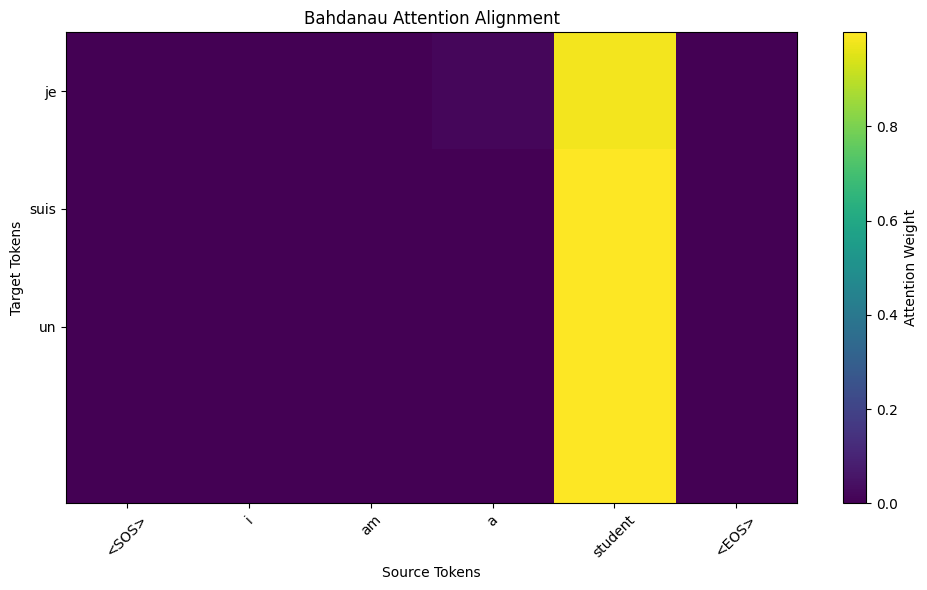

In [34]:
# PLOT ATTENTION

plot_attention(
    attention_history,
    source_tokens,
    target_tokens
)
